# Отчет по Контрольному Рубежу №1
**Студент:** Штыка Д.А
**Группа:** ИУ5-35Б
**Вариант:** 23 (задачи: 2, 5, 2)

## Задание 1. Команды Linux (задача 2)
**Условие:** список всех выполняемых процессов переписать в файл **Task_1**. Создать в каталоге **sandbox** каталог **sandbox-2**, переместить туда файлы **Task_2, Task_3**. Переписать содержимое файла **/bin/ls** в файл **Task_2**, переименовав его в "**myls**", установить права доступа на файл "**myls**" - "**r-xr--r--**". Добавить в файл **Task_3** информацию о ядре системы.

**Файл:** `RK1/task1/task1.txt`

In [ ]:
ps aux > sandbox/Task_1
mkdir sandbox/sandbox-2
mv sandbox/Task_2 sandbox/Task_3 sandbox/sandbox-2/
cat /bin/ls > sandbox/sandbox-2/Task_2
mv sandbox/sandbox-2/Task_2 sandbox/sandbox-2/myls
chmod 544 sandbox/sandbox-2/myls
uname -a >> sandbox/sandbox-2/Task_3

**Результат выполнения:**

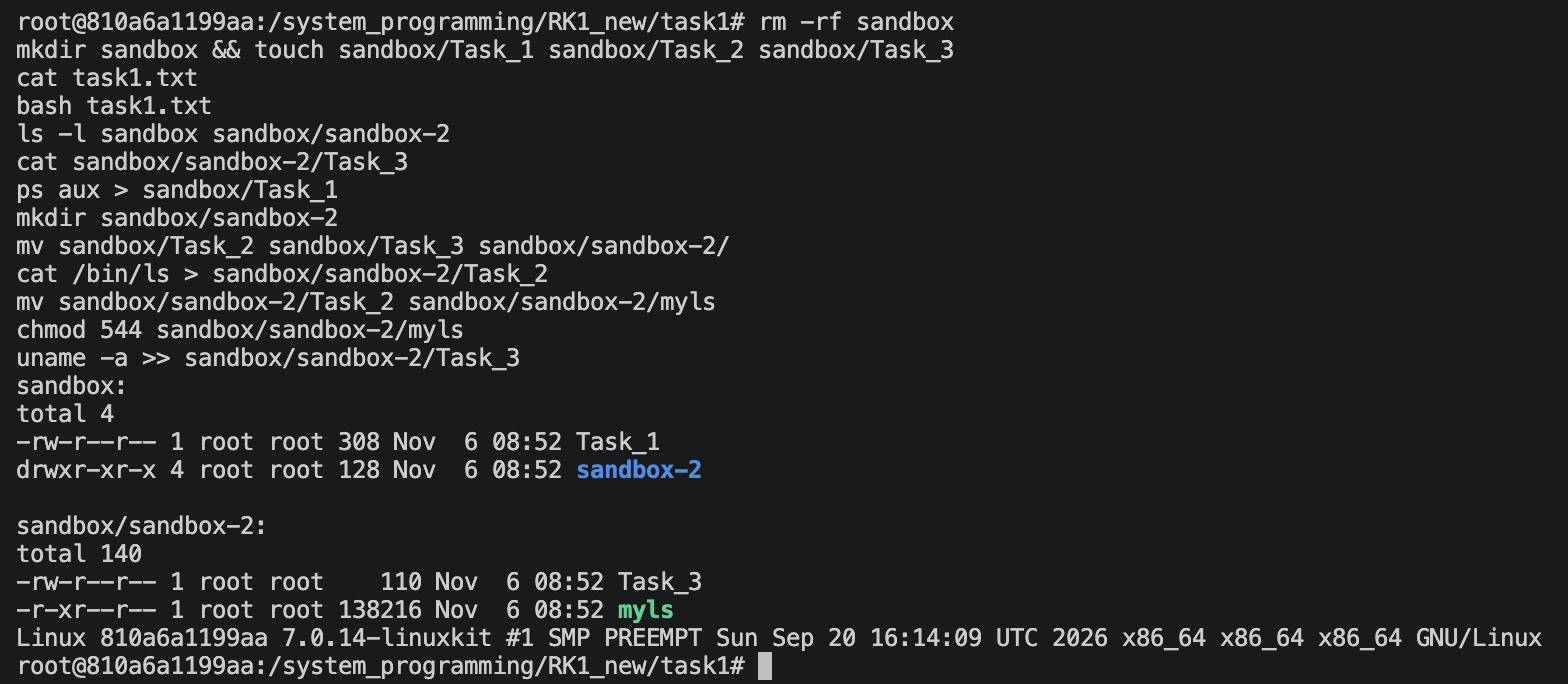

## Задание 2. Вычислительная задача (задача 5)
**Условие:** программа на ассемблере принимает параметр командной строки $n$ и выводит значение выражения $$\sum_{k=1}^n k\cdot first\_digit(k)$$где $first\_digit(k)$ - первая значащая цифра числа $k$.

**Файл:** `RK1/task2/task2.asm`

In [ ]:
format ELF64
public _start

section '.data' writable
    buf     rb 32
    err_msg db 'Usage: ./task2 n', 0x0A
    err_len = $ - err_msg

section '.text' executable
_start:
    cmp qword [rsp], 2
    jl usage
    mov rsi, [rsp+16]
    xor rbx, rbx

parse:
    movzx rax, byte [rsi]
    test al, al
    jz calc
    cmp al, '0'
    jl usage
    cmp al, '9'
    jg usage
    sub al, '0'
    imul rbx, 10
    add rbx, rax
    inc rsi
    jmp parse

calc:
    xor r12, r12
    mov r13, 1
    mov r14, 10

sum_loop:
    cmp r13, rbx
    jg print_res
    mov rax, r13
first_digit:
    xor rdx, rdx
    div r14
    test rax, rax
    jnz first_digit
    imul rdx, r13
    add r12, rdx
    inc r13
    jmp sum_loop

print_res:
    mov rax, r12
    mov rdi, buf + 31
    mov byte [rdi], 0x0A
    mov rbx, 10
conv:
    xor rdx, rdx
    div rbx
    add dl, '0'
    dec rdi
    mov [rdi], dl
    test rax, rax
    jnz conv

    mov rsi, rdi
    mov rdx, buf + 32
    sub rdx, rdi
    mov rax, 1
    mov rdi, 1
    syscall

    mov rax, 60
    xor rdi, rdi
    syscall

usage:
    mov rax, 1
    mov rdi, 2
    mov rsi, err_msg
    mov rdx, err_len
    syscall
    mov rax, 60
    mov rdi, 1
    syscall

**Результат выполнения:**

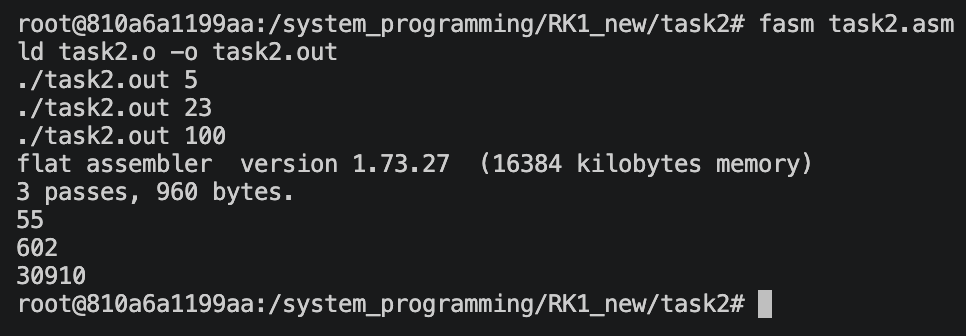

## Задание 3. Работа с файлами (задача 2)
**Условие:** программа на ассемблере принимает два параметра командной строки: имя каталога **name** и число $n$. Программа заходит в данный каталог и создает в нем новый каталог с именем **name**, далее заходит в каталог `./name/name` и создает там новый каталог **name**, делая так $n$ раз.

**Файл:** `RK1/task3/task3.asm` (использует библиотеку `func.asm`, приведена ниже)

In [ ]:
format ELF64
public _start

include 'func.asm'

section '.text' executable
_start:
   pop rcx
   mov r12, [rsp+8]
   mov rsi, [rsp+16]
   call str_number
   mov rbx, rax
   mov rax, 80
   mov rdi, r12
   syscall
.loop:
   cmp rbx, 0
   je .done
   mov rax, 83
   mov rdi, r12
   mov rsi, 777o
   syscall
   mov rax, 80
   mov rdi, r12
   syscall
   dec rbx
   jmp .loop
.done:
   call exit

**Файл:** `RK1/task3/func.asm`

In [ ]:
exit:
     mov rax, 60
     mov rdi, 0
     syscall

print_str:
    push rax
    push rdi
    push rdx
    push rcx
    mov rax, rsi
    call len_str
    mov rdx, rax
    mov rax, 1
    mov rdi, 1
    syscall
    pop rcx
    pop rdx
    pop rdi
    pop rax
    ret

new_line:
   push rax
   push rdi
   push rsi
   push rdx
   push rcx
   mov rax, 0xA
   push rax
   mov rdi, 1
   mov rsi, rsp
   mov rdx, 1
   mov rax, 1
   syscall
   pop rax
   pop rcx
   pop rdx
   pop rsi
   pop rdi
   pop rax
   ret

len_str:
  push rdx
  mov rdx, rax
  .iter:
      cmp byte [rax], 0
      je .next
      inc rax
      jmp .iter
  .next:
     sub rax, rdx
     pop rdx
     ret

str_number:
    push rcx
    push rbx

    xor rax,rax
    xor rcx,rcx
.loop:
    xor     rbx, rbx
    mov     bl, byte [rsi+rcx]
    cmp     bl, 48
    jl      .finished
    cmp     bl, 57
    jg      .finished

    sub     bl, 48
    add     rax, rbx
    mov     rbx, 10
    mul     rbx
    inc     rcx
    jmp     .loop

.finished:
    cmp     rcx, 0
    je      .restore
    mov     rbx, 10
    div     rbx

.restore:
    pop rbx
    pop rcx
    ret

number_str:
  push rbx
  push rcx
  push rdx
  xor rcx, rcx
  mov rbx, 10
  .loop_1:
    xor rdx, rdx
    div rbx
    add rdx, 48
    push rdx
    inc rcx
    cmp rax, 0
    jne .loop_1
  xor rdx, rdx
  .loop_2:
    pop rax
    mov byte [rsi+rdx], al
    inc rdx
    dec rcx
    cmp rcx, 0
  jne .loop_2
  mov byte [rsi+rdx], 0
  pop rdx
  pop rcx
  pop rbx
  ret

input_keyboard:
  push rax
  push rdi
  push rdx

  mov rax, 0
  mov rdi, 0
  mov rdx, 255
  syscall

  xor rcx, rcx
  .loop:
     mov al, [rsi+rcx]
     inc rcx
     cmp rax, 0x0A
     jne .loop
  dec rcx
  mov byte [rsi+rcx], 0

  pop rdx
  pop rdi
  pop rax
  ret

**Результат выполнения:**

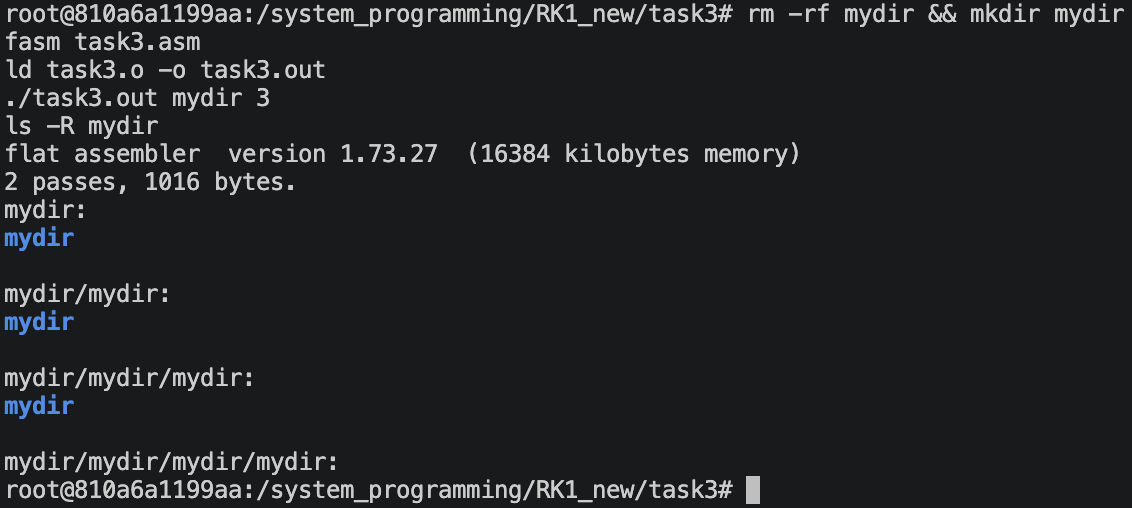